# Results plots

Draws the graphs for the report from the files in `analysis/`. This notebook **only plots**. It does not calculate any scores.

1. Make the files: run `python src/analysis.py` in the terminal (after your methods have saved their predictions).
2. Select the **birds** kernel (top right).
3. Set `SPLIT` in the first cell, then **Run All**.

Every figure is also saved as a png in `analysis/figures/`.

In [2]:
import csv
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

SPLIT = "test"   # "test" for the final report figures, "val" while tuning

# find the analysis folder (works from the project folder or from notebooks/)
ROOT = Path.cwd()
if not (ROOT / "analysis").exists() and (ROOT.parent / "analysis").exists():
    ROOT = ROOT.parent
ANALYSIS = ROOT / "analysis"
FIGURES = ANALYSIS / "figures"
if not ANALYSIS.exists():
    raise FileNotFoundError("analysis/ folder not found. Run   python src/analysis.py   first.")
FIGURES.mkdir(exist_ok=True)

TEXT_COLUMNS = {"method", "split", "image_id", "thr_source", "bin", "size_bin", "label"}


def read_csv(name):
    """Read analysis/<name> as a list of dicts. Numbers become floats, empty cells become None."""
    with open(ANALYSIS / name, newline="") as f:
        rows = list(csv.DictReader(f))
    for row in rows:
        for key, value in row.items():
            if value == "":
                row[key] = None
            elif key not in TEXT_COLUMNS:
                row[key] = float(value)
    return rows


def save(fig, name):
    path = FIGURES / f"{name}_{SPLIT}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", path)


summary = sorted((r for r in read_csv("summary.csv") if r["split"] == SPLIT),
                 key=lambda r: -r["mAP50"])
if not summary:
    raise ValueError(f"No {SPLIT} results in analysis/summary.csv. Have the methods saved {SPLIT} predictions?")
methods = [r["method"] for r in summary]                  # best method first
colors = {m: f"C{i}" for i, m in enumerate(methods)}     # one colour per method in every figure

In [3]:
info = json.loads((ANALYSIS / "info.json").read_text())
print("analysis made:", info["created"])
print("overlap needed for a correct detection (IoU):", info["iou_thr"])
for item in info["skipped"]:
    print("SKIPPED:", item["file"], "-", item["reason"])

analysis made: 2026-11-12T16:08:27
overlap needed for a correct detection (IoU): 0.5


## 1. Main results

Method        mAP@0.5  mAP@0.5:0.95  Precision  Recall     F1  Count MAE  Count RMSE  Score cut-off
m1              0.001         0.000      0.010   0.033  0.016      17.95       28.22  0.22 (val)

Score cut-off: 'self' = best F1 on val, 'val' = taken from val, 'default' = 0.5 (no val file)
saved c:\Users\troy\COMP9517\COMP9517-Bird-Detection\analysis\figures\main_results_test.png


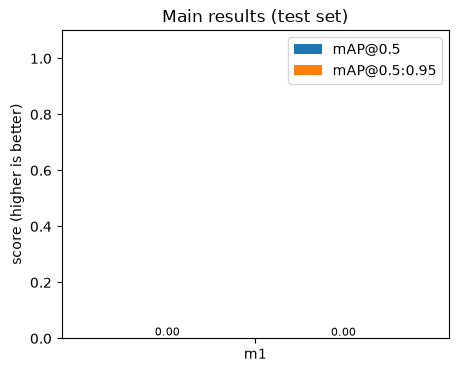

In [4]:
print(f"{'Method':<12}{'mAP@0.5':>9}{'mAP@0.5:0.95':>14}{'Precision':>11}{'Recall':>8}{'F1':>7}"
      f"{'Count MAE':>11}{'Count RMSE':>12}  Score cut-off")
for r in summary:
    print(f"{r['method']:<12}{r['mAP50']:>9.3f}{r['mAP50_95']:>14.3f}{r['precision']:>11.3f}"
          f"{r['recall']:>8.3f}{r['f1']:>7.3f}{r['count_mae']:>11.2f}{r['count_rmse']:>12.2f}"
          f"  {r['thr']:.2f} ({r['thr_source']})")
print("\nScore cut-off: 'self' = best F1 on val, 'val' = taken from val, 'default' = 0.5 (no val file)")

x, w = np.arange(len(methods)), 0.38
fig, ax = plt.subplots(figsize=(max(5, 1.6 * len(methods) + 2), 4))
bars1 = ax.bar(x - w / 2, [r["mAP50"] for r in summary], w, label="mAP@0.5")
bars2 = ax.bar(x + w / 2, [r["mAP50_95"] for r in summary], w, label="mAP@0.5:0.95")
ax.bar_label(bars1, fmt="%.2f", fontsize=8)
ax.bar_label(bars2, fmt="%.2f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylim(0, 1.1)
ax.set_ylabel("score (higher is better)")
ax.set_title(f"Main results ({SPLIT} set)")
ax.legend()
save(fig, "main_results")
plt.show()

## 2. Precision-recall curves
Each dot is the method's chosen score cut-off (best F1 on val).

saved c:\Users\troy\COMP9517\COMP9517-Bird-Detection\analysis\figures\pr_curves_test.png


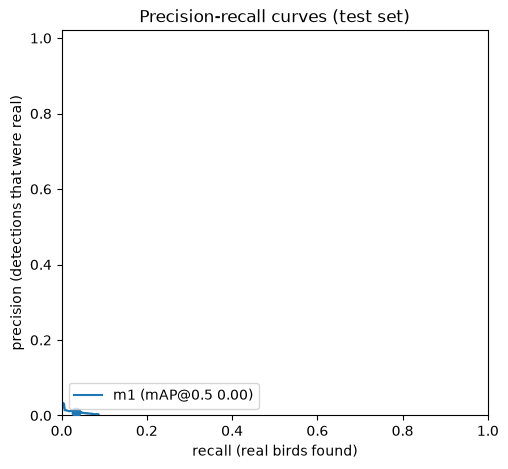

In [5]:
curves = [r for r in read_csv("pr_curves.csv") if r["split"] == SPLIT]
fig, ax = plt.subplots(figsize=(5.5, 5))
for r in summary:
    pts = [c for c in curves if c["method"] == r["method"]]
    if not pts:
        print(f"{r['method']}: no detections, no curve")
        continue
    ax.plot([c["recall"] for c in pts], [c["precision"] for c in pts],
            color=colors[r["method"]], label=f"{r['method']} (mAP@0.5 {r['mAP50']:.2f})")
    ax.scatter([r["recall"]], [r["precision"]], color=colors[r["method"]], zorder=3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("recall (real birds found)")
ax.set_ylabel("precision (detections that were real)")
ax.set_title(f"Precision-recall curves ({SPLIT} set)")
ax.legend(loc="lower left")
save(fig, "pr_curves")
plt.show()

## 3. Results by how many birds are in the image

saved c:\Users\troy\COMP9517\COMP9517-Bird-Detection\analysis\figures\density_bins_test.png


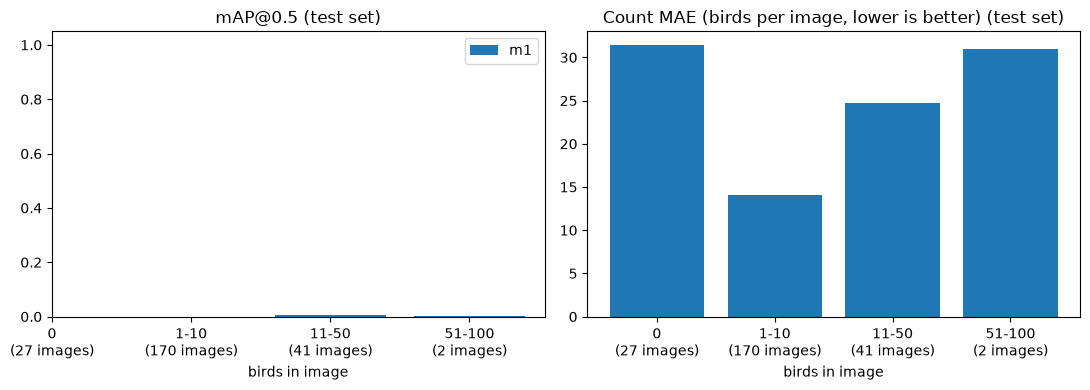

Images with NO birds: false alarms per image
  m1          31.44


In [6]:
dens = [r for r in read_csv("density_bins.csv") if r["split"] == SPLIT]
n_images = {r["bin"]: int(r["n_images"]) for r in dens}
shown = [b for b in dict.fromkeys(r["bin"] for r in dens) if n_images[b] > 0]   # skip empty groups

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bar_w = 0.8 / len(methods)
for k, m in enumerate(methods):
    rows = {r["bin"]: r for r in dens if r["method"] == m}
    for ax, key in ((axes[0], "mAP50"), (axes[1], "count_mae")):
        xs, ys = [], []
        for i, b in enumerate(shown):
            if rows[b][key] is not None:                  # mAP is undefined for images with no birds
                xs.append(i + (k - (len(methods) - 1) / 2) * bar_w)
                ys.append(rows[b][key])
        ax.bar(xs, ys, bar_w, label=m, color=colors[m])
for ax, title in zip(axes, ("mAP@0.5", "Count MAE (birds per image, lower is better)")):
    ax.set_xticks(range(len(shown)))
    ax.set_xticklabels([f"{b}\n({n_images[b]} images)" for b in shown])
    ax.set_xlabel("birds in image")
    ax.set_title(f"{title} ({SPLIT} set)")
axes[0].set_ylim(0, 1.05)
axes[0].legend()
fig.tight_layout()
save(fig, "density_bins")
plt.show()

if "0" in shown:
    print("Images with NO birds: false alarms per image")
    for m in methods:
        row = next(r for r in dens if r["method"] == m and r["bin"] == "0")
        print(f"  {m:<12}{row['fp_per_image']:.2f}")

## 4. Results by bird size
How many of the real birds were found, for small, medium and large birds (thirds of all birds).

saved c:\Users\troy\COMP9517\COMP9517-Bird-Detection\analysis\figures\size_bins_test.png


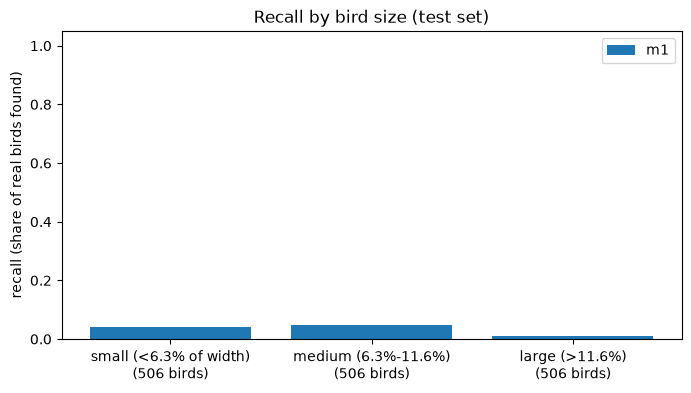

In [7]:
size = [r for r in read_csv("size_bins.csv") if r["split"] == SPLIT]
labels = list(dict.fromkeys(r["label"] for r in size))
fig, ax = plt.subplots(figsize=(8, 4))
bar_w = 0.8 / len(methods)
for k, m in enumerate(methods):
    rows = {r["label"]: r for r in size if r["method"] == m}
    xs = [i + (k - (len(methods) - 1) / 2) * bar_w for i, lab in enumerate(labels) if rows[lab]["recall"] is not None]
    ys = [rows[lab]["recall"] for lab in labels if rows[lab]["recall"] is not None]
    ax.bar(xs, ys, bar_w, label=m, color=colors[m])
counts = {r["label"]: int(r["n_birds"]) for r in size}
ax.set_xticks(range(len(labels)))
ax.set_xticklabels([f"{lab}\n({counts[lab]} birds)" for lab in labels])
ax.set_ylim(0, 1.05)
ax.set_ylabel("recall (share of real birds found)")
ax.set_title(f"Recall by bird size ({SPLIT} set)")
ax.legend()
save(fig, "size_bins")
plt.show()

## 5. Counting birds
Each dot is one image. On the dashed line the method counted exactly the right number of birds.

saved c:\Users\troy\COMP9517\COMP9517-Bird-Detection\analysis\figures\count_scatter_test.png


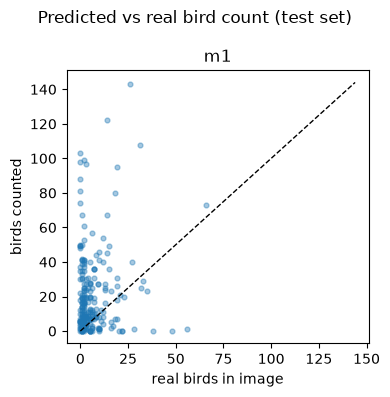

In [8]:
per_image = [r for r in read_csv("per_image.csv") if r["split"] == SPLIT]
cols = min(3, len(methods))
n_rows = int(np.ceil(len(methods) / cols))
fig, axes = plt.subplots(n_rows, cols, figsize=(4 * cols, 4 * n_rows), squeeze=False)
top = max(max(r["n_gt"], r["n_pred"]) for r in per_image) + 1
for ax, m in zip(axes.flat, methods):
    pts = [r for r in per_image if r["method"] == m]
    ax.scatter([r["n_gt"] for r in pts], [r["n_pred"] for r in pts], s=12, alpha=0.4, color=colors[m])
    ax.plot([0, top], [0, top], "k--", linewidth=1)
    ax.set_title(m)
    ax.set_xlabel("real birds in image")
    ax.set_ylabel("birds counted")
for ax in list(axes.flat)[len(methods):]:
    ax.axis("off")
fig.suptitle(f"Predicted vs real bird count ({SPLIT} set)")
fig.tight_layout()
save(fig, "count_scatter")
plt.show()

## Still to add

- mAP vs severity, and mAP vs data fraction / label noise. These need the variants of each method (different severities, data fractions or label noise levels) to be saved as separate predictions with an agreed naming rule. Then they can be added to `analysis.py` and plotted here.
- Training time, inference time per image and hardware (not in the predictions files).